# 🔧 Config

In [273]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from sklearn.preprocessing import (
    OneHotEncoder,
    FunctionTransformer
    )
from sklearn.compose import (
    ColumnTransformer,
    make_column_selector
)
from sklearn.pipeline import Pipeline
from sklearn.base import BaseEstimator, TransformerMixin

# custom modules
import data_loader
import data_visualizer

In [274]:
PATH_DATA ='data/raw/Telco_customer_churn.xlsx'

FIGSIZE = (12, 6)

SEED = 4586

# 📝 Definição de problema e escopo (CRISP-DM)
## Business Understanding
> - ❔ A diretoria precisa de um modelo preditivo de churn que **classifique clientes** com risco de cancelamento

### ✅ Critérios de sucesso
> - 🎯 Reduzir em 20% a taxa de churn trimestral, identificando clientes em risco com **antecedência** para ações de retenção
> - 💡**Interpretabilidade** - O modelo deverá ser utilizável e explicável para usuários sem conhecimento tecnológico aprofundado
> - ✅ Compliance LGPD

#### 📈 KPI
> - 🎯 Taxa de Churn

#### 📈 Dados técnicos
> - 🎯 O modelo deverá nos retornar uma classificação binária: se está em risco de churn, ou não
> - 📈 Recall >= 0.80
> - 📈 Precision >= 0.65

### 👥 Recursos
> - 👥 1 Engenheiro
> - 💻 5000+ registros para análise
> - 🛜 Infraestrutura simples FastAPI
> - 👥 Envolvimento Stakeholders: Suporte técnico, CRM e Call Center

### ❗ Restrições
> - ❗ Temos 7000+ registros
> - 🗺️ O modelo terá sua performance garantida apenas dentro da região geográfica abrangida na base de dados
> - 🏬 O modelo terá sua performance garantida apenas com clientes dessa instituição

### 📅 Cronograma
> - 📅 O modelo deverá estar pronto até 19/01/2027

### 🛠️ Ferramentas
> - 🐍 Python (pandas, scikit-learn)

### 🔧 Manutenção
> - ⌚ O modelo deve ser re-treinado e testado a cada trimestre

### 📓 Entrega esperada
> - 🏆 Um modelo exposto via FastAPI que entrega classificações à dados fornecidos, a ser entregue para a equipe de CRM
> - ❌**Não** será desenvolvido a estrutura para rodar o modelo automaticamente 

# 📈 Carregamento dos dados
Checagem inicial dos dados

Colunas descritas no [Kaggle](https://www.kaggle.com/datasets/yeanzc/telco-customer-churn-ibm-dataset):


| Value | Description | Options |
| --- | --- | --- |
| **CustomerID** | A unique ID that identifies each customer. | - |
| **Count** | A value used in reporting/dashboarding to sum up<br>the number of customers in a filtered set. | - |
| **Country** | The country of the customer’s primary residence. | - |
| **State** | The state of the customer’s primary residence. | - |
| **City** | The city of the customer’s primary residence. | - |
| **Zip Code** | The zip code of the customer’s primary residence. | - |
| **Lat Long** | The combined latitude and longitude of the customer’s primary residence. | - |
| **Latitude** | The latitude of the customer’s primary residence. | - |
| **Longitude** | The longitude of the customer’s primary residence. | - |
| **Gender** | The customer’s gender | Male, Female |
| **Senior Citizen** | Indicates if the customer is 65 or older | Yes, No |
| **Partner** | Indicate if the customer has a partner | Yes, No |
| **Dependents** | Indicates if the customer lives with any dependents | Yes, No.<br>Dependents could be children,<br>parents, grandparents, etc. |
| **Tenure Months** | Indicates the total amount of months that the customer has been<br>with the company by the end of the quarter specified above. | - |
| **Phone Service** | Indicates if the customer subscribes to home phone service<br>with the company | Yes, No |
| **Multiple Lines** | Indicates if the customer subscribes to multiple<br>telephone lines with the company | Yes, No |
| **Internet Service** | Indicates if the customer subscribes to<br>Internet service with the company | No, DSL, Fiber Optic, Cable. |
| **Online Security** | Indicates if the customer subscribes to an additional<br>online security service provided by the company | Yes, No |
| **Online Backup** | Indicates if the customer subscribes to an additional<br>online backup service provided by the company | Yes, No |
| **Device Protection** | Indicates if the customer subscribes to an additional<br>device protection plan for their Internet equipment provided by the company | Yes, No |
| **Tech Support** | Indicates if the customer subscribes to an additional<br>technical support plan from the company with reduced wait times | Yes, No |
| **Streaming TV** | Indicates if the customer uses their Internet service<br>to stream television programing from a third party provider | Yes, No.<br>The company does not charge<br>an additional fee for this service. |
| **Streaming Movies** | Indicates if the customer uses their Internet service<br>to stream movies from a third party provider | Yes, No.<br>The company does not charge<br>an additional fee for this service. |
| **Contract** | Indicates the customer’s current contract type | Month-to-Month, One Year, Two Year. |
| **Paperless Billing** | Indicates if the customer has chosen paperless billing | Yes, No |
| **Payment Method** | Indicates how the customer pays their bill | Bank Withdrawal, Credit Card, Mailed Check |
| **Monthly Charge** | Indicates the customer’s current total monthly charge for all their services from the company. | - |
| **Total Charges** | Indicates the customer’s total charges, calculated to the end of the quarter specified above. | - |
| **Churn Label** | - | Yes = the customer left the company this quarter.<br>No = the customer remained with the company.<br>Directly related to Churn Value. |
| **Churn Value** | - | 1 = the customer left the company this quarter.<br>0 = the customer remained with the company.<br>Directly related to Churn Label. |
| **Churn Score** | A value from 0-100 that is calculated using the predictive tool IBM SPSS Modeler.<br>The model incorporates multiple factors known to cause churn.<br>The higher the score, the more likely the customer will churn. | - |
| **CLTV** | Customer Lifetime Value.<br>A predicted CLTV is calculated using corporate formulas and existing data.<br>The higher the value, the more valuable the customer.<br>High value customers should be monitored for churn. | - |
| **Churn Reason** | A customer’s specific reason for leaving the company. Directly related to Churn Category. | - |

In [275]:
df = data_loader.load_churn_data(PATH_DATA)

df.sample(n=5,random_state=SEED)

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
5645,4903-CNOZC,1,United States,California,La Canada Flintridge,91011,"34.234912, -118.153729",34.234912,-118.153729,Male,No,No,No,29,Yes,Yes,DSL,No,Yes,Yes,No,No,Yes,One year,No,Credit card (automatic),70.90,1964.6,No,0,29,2064,NaN
5859,4049-ZPALD,1,United States,California,Forest Falls,92339,"34.067699, -116.903891",34.067699,-116.903891,Female,No,Yes,No,64,Yes,No,Fiber optic,Yes,No,Yes,No,Yes,Yes,Two year,Yes,Bank transfer (automatic),99.00,6375.8,No,0,68,5483,NaN
1101,4088-YLDSU,1,United States,California,Redwood City,94062,"37.410567, -122.297152",37.410567,-122.297152,Male,No,Yes,No,55,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,One year,Yes,Electronic check,104.15,5743.05,Yes,1,86,4369,Competitor had better devices
594,1583-IHQZE,1,United States,California,Camarillo,93010,"34.227846, -119.079903",34.227846,-119.079903,Male,No,No,No,12,Yes,Yes,Fiber optic,No,Yes,Yes,Yes,Yes,Yes,Month-to-month,Yes,Mailed check,112.95,1384.75,Yes,1,97,3965,Attitude of support person
4773,4537-CIBHB,1,United States,California,Arvin,93203,"35.116307, -118.817644",35.116307,-118.817644,Female,No,Yes,Yes,9,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,No,Mailed check,20.25,172.35,No,0,48,4272,NaN


In [276]:
df.describe()

,Count,Zip Code,Latitude,Longitude,Tenure Months,Monthly Charges,Churn Value,Churn Score,CLTV
count,7043.0,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,1.0,93521.964646,36.282441,-119.798880,32.371149,64.761692,0.265370,58.699418,4400.295755
std,0.0,1865.794555,2.455723,2.157889,24.559481,30.090047,0.441561,21.525131,1183.057152
min,1.0,90001.000000,32.555828,-124.301372,0.000000,18.250000,0.000000,5.000000,2003.000000
25%,1.0,92102.000000,34.030915,-121.815412,9.000000,35.500000,0.000000,40.000000,3469.000000
50%,1.0,93552.000000,36.391777,-119.730885,29.000000,70.350000,0.000000,61.000000,4527.000000
75%,1.0,95351.000000,38.224869,-118.043237,55.000000,89.850000,1.000000,75.000000,5380.500000
max,1.0,96161.000000,41.962127,-114.192901,72.000000,118.750000,1.000000,100.000000,6500.000000


In [277]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   str    
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   str    
 3   State              7043 non-null   str    
 4   City               7043 non-null   str    
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   str    
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   str    
 10  Senior Citizen     7043 non-null   str    
 11  Partner            7043 non-null   str    
 12  Dependents         7043 non-null   str    
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   str    
 15  Multiple Lines     7043 non-null   str    
 16  Internet Service   7043 non-null   

Formatando colunas

In [278]:
df.columns = data_loader.format_column_names(list(df.columns))

df.columns

Index(['customerid', 'count', 'country', 'state', 'city', 'zip_code',
       'lat_long', 'latitude', 'longitude', 'gender', 'senior_citizen',
       'partner', 'dependents', 'tenure_months', 'phone_service',
       'multiple_lines', 'internet_service', 'online_security',
       'online_backup', 'device_protection', 'tech_support', 'streaming_tv',
       'streaming_movies', 'contract', 'paperless_billing', 'payment_method',
       'monthly_charges', 'total_charges', 'churn_label', 'churn_value',
       'churn_score', 'cltv', 'churn_reason'],
      dtype='str')

In [279]:
df[['churn_label', 'churn_value', 'churn_score', 'churn_reason']].sample(5, random_state=SEED)

,churn_label,churn_value,churn_score,churn_reason
5645,No,0,29,NaN
5859,No,0,68,NaN
1101,Yes,1,86,Competitor had better devices
594,Yes,1,97,Attitude of support person
4773,No,0,48,NaN


In [280]:
df[['latitude', 'longitude', 'lat_long']].sample(5, random_state=SEED)

,latitude,longitude,lat_long
5645,34.234912,-118.153729,"34.234912, -118.153729"
5859,34.067699,-116.903891,"34.067699, -116.903891"
1101,37.410567,-122.297152,"37.410567, -122.297152"
594,34.227846,-119.079903,"34.227846, -119.079903"
4773,35.116307,-118.817644,"35.116307, -118.817644"


In [281]:
data : dict = {'column':[],'unique_values':[],'missing_values':[]}

for col in df.columns:
    unique_values_count : int = df[col].nunique()
    missing_values_count : int = df[col].isna().sum()

    data['column'].append(col)
    data['unique_values'].append(unique_values_count)
    data['missing_values'].append(missing_values_count)

df_value_data = pd.DataFrame(
    data=data
).set_index('column')

df_value_data

,unique_values,missing_values
column,,
customerid,7043,0
count,1,0
country,1,0
state,1,0
city,1129,0
zip_code,1652,0
lat_long,1652,0
latitude,1652,0
longitude,1651,0


Temos dados de apenas um país e estado. O modelo portanto só terá garantia de qualidade dentro desses parâmetros, e os dados de latitude e longitude estão dentro desses limites.

In [282]:
country : str = df['country'].values[0]
state : str = df['state'].values[0]

print(f'We only have data froun {state.upper()}, {country.upper()}')

We only have data froun CALIFORNIA, UNITED STATES


Separando as colunas em categorias...
## Categorização de colunas

In [283]:
binary_candidates = df_value_data[df_value_data['unique_values'] == 2].index
df[binary_candidates].head()

,gender,senior_citizen,partner,dependents,phone_service,paperless_billing,churn_label,churn_value
0,Male,No,No,No,Yes,Yes,Yes,1
1,Female,No,No,Yes,Yes,Yes,Yes,1
2,Female,No,No,Yes,Yes,Yes,Yes,1
3,Female,No,Yes,Yes,Yes,Yes,Yes,1
4,Male,No,No,Yes,Yes,Yes,Yes,1


In [284]:
# TRUE or FALSE
COLS_BINARY : list[str] = ['senior_citizen', 'partner', 'dependents', 'phone_service', 'paperless_billing']

COL_TARGET : str = 'churn_value'

# gender will be handled as a categorical

In [285]:
categorical_candidates = df_value_data[df_value_data['unique_values'] >= 2].index
categorical_candidates_narrowed = [candidate for candidate in categorical_candidates if candidate not in COLS_BINARY]
df_categorical_candidates = df[categorical_candidates_narrowed].head().T
df_categorical_candidates['unique_values'] = 0
for i in df_categorical_candidates.index:
    df_categorical_candidates.loc[i, 'unique_values'] = df_value_data.loc[i, 'unique_values']
df_categorical_candidates

,0,1,2,3,4,unique_values
customerid,3668-QPYBK,9237-HQITU,9305-CDSKC,7892-POOKP,0280-XJGEX,7043
city,Los Angeles,Los Angeles,Los Angeles,Los Angeles,Los Angeles,1129
zip_code,90003,90005,90006,90010,90015,1652
lat_long,"33.964131, -118.272783","34.059281, -118.30742","34.048013, -118.293953","34.062125, -118.315709","34.039224, -118.266293",1652
latitude,33.964131,34.059281,34.048013,34.062125,34.039224,1652
longitude,-118.272783,-118.30742,-118.293953,-118.315709,-118.266293,1651
gender,Male,Female,Female,Female,Male,2
tenure_months,2,2,8,28,49,73
multiple_lines,No,No,Yes,Yes,Yes,3
internet_service,DSL,Fiber optic,Fiber optic,Fiber optic,Fiber optic,3


In [286]:
binary_with_exception_candidates = df_value_data[df_value_data['unique_values'].between(3, 4)].index

for candidate in binary_with_exception_candidates:
    print(df[candidate].value_counts())
    print()

multiple_lines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

internet_service
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

online_security
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

online_backup
No                     3088
Yes                    2429
No internet service    1526
Name: count, dtype: int64

device_protection
No                     3095
Yes                    2422
No internet service    1526
Name: count, dtype: int64

tech_support
No                     3473
Yes                    2044
No internet service    1526
Name: count, dtype: int64

streaming_tv
No                     2810
Yes                    2707
No internet service    1526
Name: count, dtype: int64

streaming_movies
No                     2785
Yes                    2732
No internet service    1526
Name: count, dtype: int64

contract
Month-to-mont

In [287]:
df_categorical_candidates.index

Index(['customerid', 'city', 'zip_code', 'lat_long', 'latitude', 'longitude',
       'gender', 'tenure_months', 'multiple_lines', 'internet_service',
       'online_security', 'online_backup', 'device_protection', 'tech_support',
       'streaming_tv', 'streaming_movies', 'contract', 'payment_method',
       'monthly_charges', 'total_charges', 'churn_label', 'churn_value',
       'churn_score', 'cltv', 'churn_reason'],
      dtype='str')

Colocaremos em uma categoria separada as colunas binárias que tem uma "terceira opção", pois dependem de uma coluna externa para serem aplicáveis (por exemplo, só se pode ter múltiplas linhas de telefone se o cliente assina o serviço de telefone)

In [288]:
# data within a defined set of expected results
COLS_CATEGORICAL : list[str] = ['gender', 'internet_service', 'contract', 'payment_method', 'city']

# TRUE or FALSE with a 'non-applicable' option, that depend on another column
COLS_DEPENDANT_BINARIES : list[str] = ['multiple_lines', 'online_security', 'online_backup', 'device_protection', 'tech_support', 'streaming_tv', 'streaming_movies']

col_dependencies : dict = {
    'multiple_lines':'phone_service',
    'online_security':'internet_service',
    'online_backup':'internet_service',
    'device_protection':'internet_service',
    'tech_support':'internet_service', 
    'streaming_tv':'internet_service',
    'streaming_movies':'internet_service'
}

# numerical data
# since we do not know how cltv is calculated, we will drop it to avoid leakage
COLS_NUMERICAL : list[str] = ['latitude', 'longitude', 'tenure_months', 'total_charges', 'monthly_charges']

In [289]:
print(f'TODOS as contagens de valores')
print('='*10)
for col in col_dependencies.keys():
    display(df[[col, col_dependencies.get(col)]].value_counts())

print(f'\nContagens de valores onde a dependência é NÃO')
print('='*10)
for col in col_dependencies.keys():
    display(df[[col, col_dependencies.get(col)]].loc[df[col_dependencies.get(col)] == 'No'].value_counts())

TODOS as contagens de valores


multiple_lines    phone_service
No                Yes              3390
Yes               Yes              2971
No phone service  No                682
Name: count, dtype: int64

online_security      internet_service
No                   Fiber optic         2257
No internet service  No                  1526
No                   DSL                 1241
Yes                  DSL                 1180
                     Fiber optic          839
Name: count, dtype: int64

online_backup        internet_service
No                   Fiber optic         1753
No internet service  No                  1526
Yes                  Fiber optic         1343
No                   DSL                 1335
Yes                  DSL                 1086
Name: count, dtype: int64

device_protection    internet_service
No                   Fiber optic         1739
No internet service  No                  1526
Yes                  Fiber optic         1357
No                   DSL                 1356
Yes                  DSL                 1065
Name: count, dtype: int64

tech_support         internet_service
No                   Fiber optic         2230
No internet service  No                  1526
No                   DSL                 1243
Yes                  DSL                 1178
                     Fiber optic          866
Name: count, dtype: int64

... (6 outputs left out)

device_protection    internet_service
No internet service  No                  1526
Name: count, dtype: int64

tech_support         internet_service
No internet service  No                  1526
Name: count, dtype: int64

streaming_tv         internet_service
No internet service  No                  1526
Name: count, dtype: int64

streaming_movies     internet_service
No internet service  No                  1526
Name: count, dtype: int64

## Dataframe categorizado

In [290]:
print(f'The original DataFrame has {len(df.columns)} columns')
print(f'We have categorized {len(COLS_BINARY) + len(COLS_NUMERICAL) + len(COLS_CATEGORICAL) + len(COLS_DEPENDANT_BINARIES) + len([COL_TARGET])} of them')

print(f'\nRemaining columns\n{[col for col in df.columns if col not in COLS_BINARY + COLS_NUMERICAL + COLS_CATEGORICAL + COLS_DEPENDANT_BINARIES + [COL_TARGET]]}')

The original DataFrame has 33 columns
We have categorized 23 of them

Remaining columns
['customerid', 'count', 'country', 'state', 'zip_code', 'lat_long', 'churn_label', 'churn_score', 'cltv', 'churn_reason']


Na fase de treinamento, descartaremos as colunas redundantes ou irrelevantes para nossa análise, mantendo apenas as que categorizamos. 

In [291]:
# these columns will be discarded once we enter the ML phase
COLS_DISCARD : list[str] = ['customerid', 'count', 'country', 'state', 'zip_code', 'lat_long', 'churn_label', 'churn_score', 'churn_reason', 'cltv']

# joining columns in desired order
cols_to_analyze : list[str] = [COL_TARGET] + COLS_NUMERICAL + COLS_CATEGORICAL + COLS_BINARY + COLS_DEPENDANT_BINARIES

df = df[cols_to_analyze]

print(df.shape)
print(df.columns)

(7043, 23)
Index(['churn_value', 'latitude', 'longitude', 'tenure_months',
       'total_charges', 'monthly_charges', 'gender', 'internet_service',
       'contract', 'payment_method', 'city', 'senior_citizen', 'partner',
       'dependents', 'phone_service', 'paperless_billing', 'multiple_lines',
       'online_security', 'online_backup', 'device_protection', 'tech_support',
       'streaming_tv', 'streaming_movies'],
      dtype='str')


# 🔍 EDA

In [292]:
positive_color : str = "#259e00"
negative_color : str = "#741B2A"

missing_color : str = "#c0c0c0"
neutral_color : str = "#8f8f8f"

label_color_dict = {
    'Yes': positive_color,
    1:positive_color,
    'No':negative_color,
    0:negative_color,
    'No internet service':missing_color,
    'No phone service': missing_color,
    'Outros':neutral_color
}

generic_colors : list[str] = [
    '#00415e',
    '#2e4d81',
    '#655399',
    '#a0529f',
    '#d54f91',
    '#fa5a73',
    '#ff7a49',
    '#ffa600',
]

title_ax_defaults : dict = {
    'fontsize' : 10,
    'fontweight' : 'bold',
    'fontstyle' : 'normal',
    'fontfamily' : 'sans-serif',
    'color' : '#000000'
}

title_fig_defaults : dict = {
    'fontsize' : 14,
    'fontweight' : 'bold',
    'fontstyle' : 'normal',
    'fontfamily' : 'sans-serif',
    'color' : '#000000'
}

## 🎯 Variável TARGET

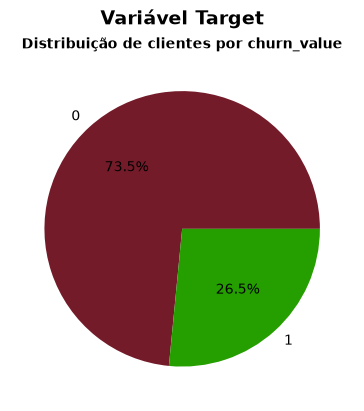

In [293]:
data_visualizer.plot_value_counts_pie(
    data=df[[COL_TARGET]],
    figsize=(8, 4),
    fig_title='Variável Target',
    ncols=1,
    color_dict=label_color_dict,
    generic_colors=generic_colors,
    title_args = title_ax_defaults,
    suptitle_args = title_fig_defaults
    )
plt.show()

In [294]:
df[[COL_TARGET]].value_counts()

churn_value
0              5174
1              1869
Name: count, dtype: int64

A variável Target é **desbalanceada**. Temos apenas 26.5% de clientes que cancelaram.

>- 💡 **Conclusão:** Não utilizaremos acurácia, mas em vez disso uma mistura de precision e recall. Priorizaremos o recall (>0.80), mas exigiremos também um precision moderado (>0.65). Faremos essa análise com AUC-PR e AUC-ROC

A partir daqui, compararemos duas distribuição de todos os clientes, e dos clientes que cancelaram (churn) nas nossas variáveis.

In [295]:
df_churn_only = df.loc[df[COL_TARGET] == 1]
df_churn_only.head(3)

,churn_value,latitude,longitude,tenure_months,total_charges,monthly_charges,gender,internet_service,contract,payment_method,city,senior_citizen,partner,dependents,phone_service,paperless_billing,multiple_lines,online_security,online_backup,device_protection,tech_support,streaming_tv,streaming_movies
0,1,33.964131,-118.272783,2,108.15,53.85,Male,DSL,Month-to-month,Mailed check,Los Angeles,No,No,No,Yes,Yes,No,Yes,Yes,No,No,No,No
1,1,34.059281,-118.307420,2,151.65,70.70,Female,Fiber optic,Month-to-month,Electronic check,Los Angeles,No,No,Yes,Yes,Yes,No,No,No,No,No,No,No
2,1,34.048013,-118.293953,8,820.5,99.65,Female,Fiber optic,Month-to-month,Electronic check,Los Angeles,No,No,Yes,Yes,Yes,Yes,No,No,Yes,No,Yes,Yes


### 📦 Variáveis categóricas ou binárias

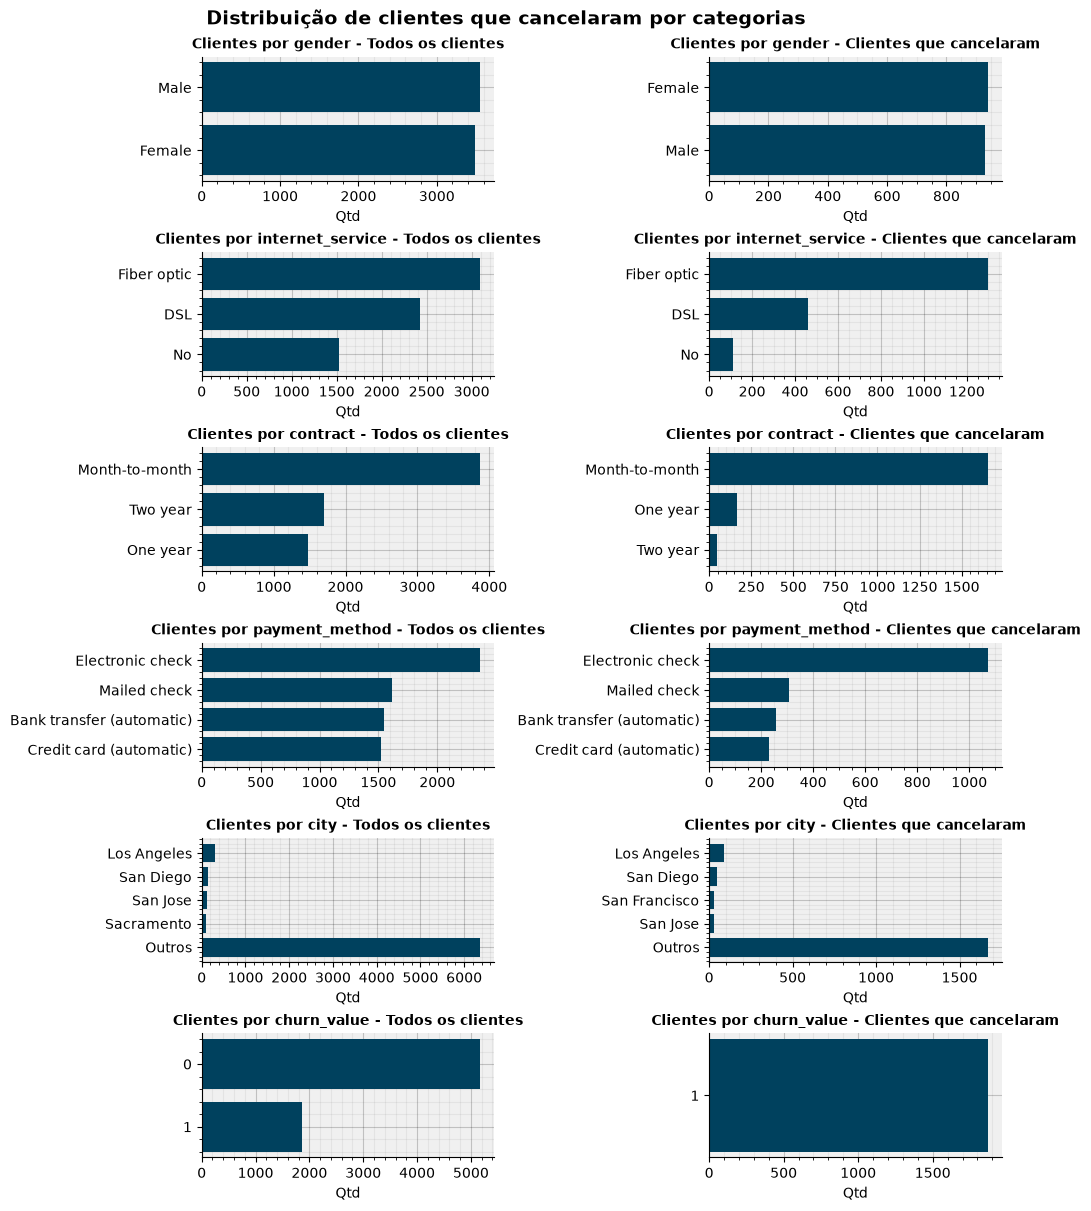

In [296]:
cols_analyzed : list = COLS_CATEGORICAL + [COL_TARGET]

data_visualizer.plot_alternating_value_counts_barh(
    data1=df[cols_analyzed],
    data2=df_churn_only[cols_analyzed],
    data1_label='Todos os clientes',
    data2_label='Clientes que cancelaram',
    ncols = 2,
    figsize=(10, 12),
    fig_title='Distribuição de clientes que cancelaram por categorias',
    # color_dict=label_color_dict,
    generic_color=generic_colors[0],
    title_args = title_ax_defaults,
    suptitle_args = title_fig_defaults,
    sort_alphabetically=False,
    max_categories=5
)
plt.show()

>- Clientes de gênero masculino e feminino se distribuem similarmente em relação ao churn; essa variável pode ser descartada pois não traz benefício à análise e requere cuidados de Fairness
>- Clientes que cancelaram utilizam a fibra ótica em maior proporção do que a população geral
>- Clientes que cancelaram estão em um plano mensal em maior proporção
>- Clientes que cancelaram pagam com cheque eletrônico em maior proporção
>- Não há correlação visível entre o cancelamento e a cidade; essa variável pode ser descartada pois não traz benefício à análise e requere cuidados de Fairness

>- 💡 **CONCLUSÃO**
>- ✅`internet_service`, `contract` e `payment_method` são variáveis de interesse
>- ❌`gender` e `city` devem ser descartadas.

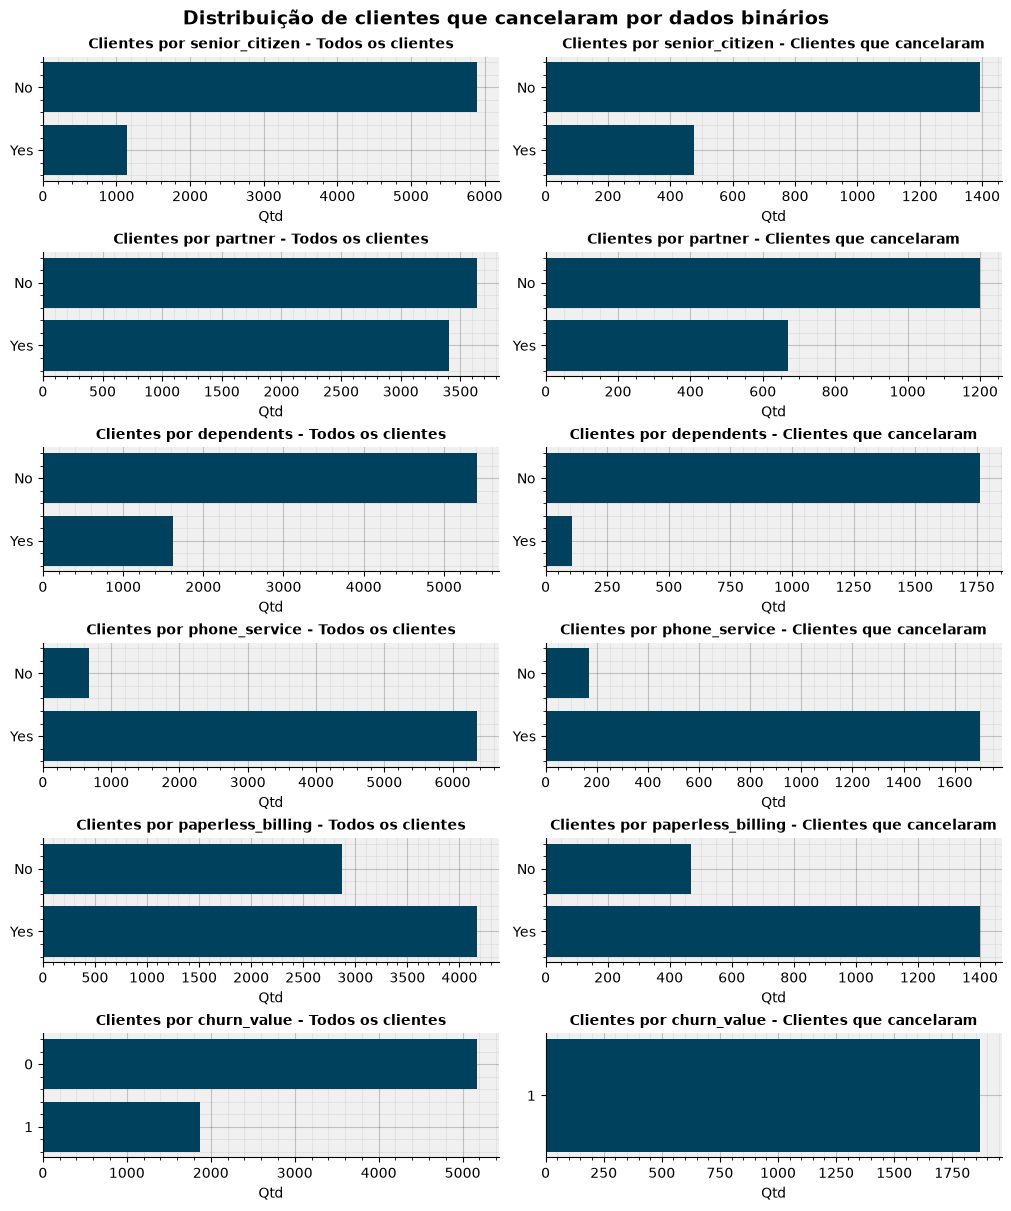

In [297]:
cols_analyzed = COLS_BINARY + [COL_TARGET]

data_visualizer.plot_alternating_value_counts_barh(
    data1=df[cols_analyzed],
    data2=df_churn_only[cols_analyzed],
    data1_label='Todos os clientes',
    data2_label='Clientes que cancelaram',
    ncols = 2,
    figsize=(10, 12),
    fig_title='Distribuição de clientes que cancelaram por dados binários',
    # color_dict=label_color_dict,
    generic_color=generic_colors[0],
    title_args = title_ax_defaults,
    suptitle_args = title_fig_defaults,
    sort_alphabetically=True,
    max_categories=5
)
plt.show()

>- Clientes idosos cancelaram em proporção levemente maior, porém, excluiremos essa categoria devido às preocupações de Fairness
>- Entre clientes que cancelaram, há uma proporção maior de solteiros
>- Entre clientes que cancelaram, há uma proporção maior de clientes que não têm dependentes
>- Não há correlação visível entre o plano de telefone e o cancelamento
>- Entre clientes que cancelaram, há uma proporção maior de clientes que recebem as contas por via digital (sem papel)

>- 💡 **CONCLUSÃO**
>- ✅`partner`, `dependents` e `paperless_billing` são variáveis de interesse
>- ❌`senior_citizen` e `phone_service` devem ser descartadas

Checando relação entre `payment_method` e `paperless_billing`

In [298]:
df[['payment_method', 'paperless_billing']].value_counts().sort_index(ascending=True)

payment_method             paperless_billing
Bank transfer (automatic)  No                    653
                           Yes                   891
Credit card (automatic)    No                    640
                           Yes                   882
Electronic check           No                    623
                           Yes                  1742
Mailed check               No                    956
                           Yes                   656
Name: count, dtype: int64

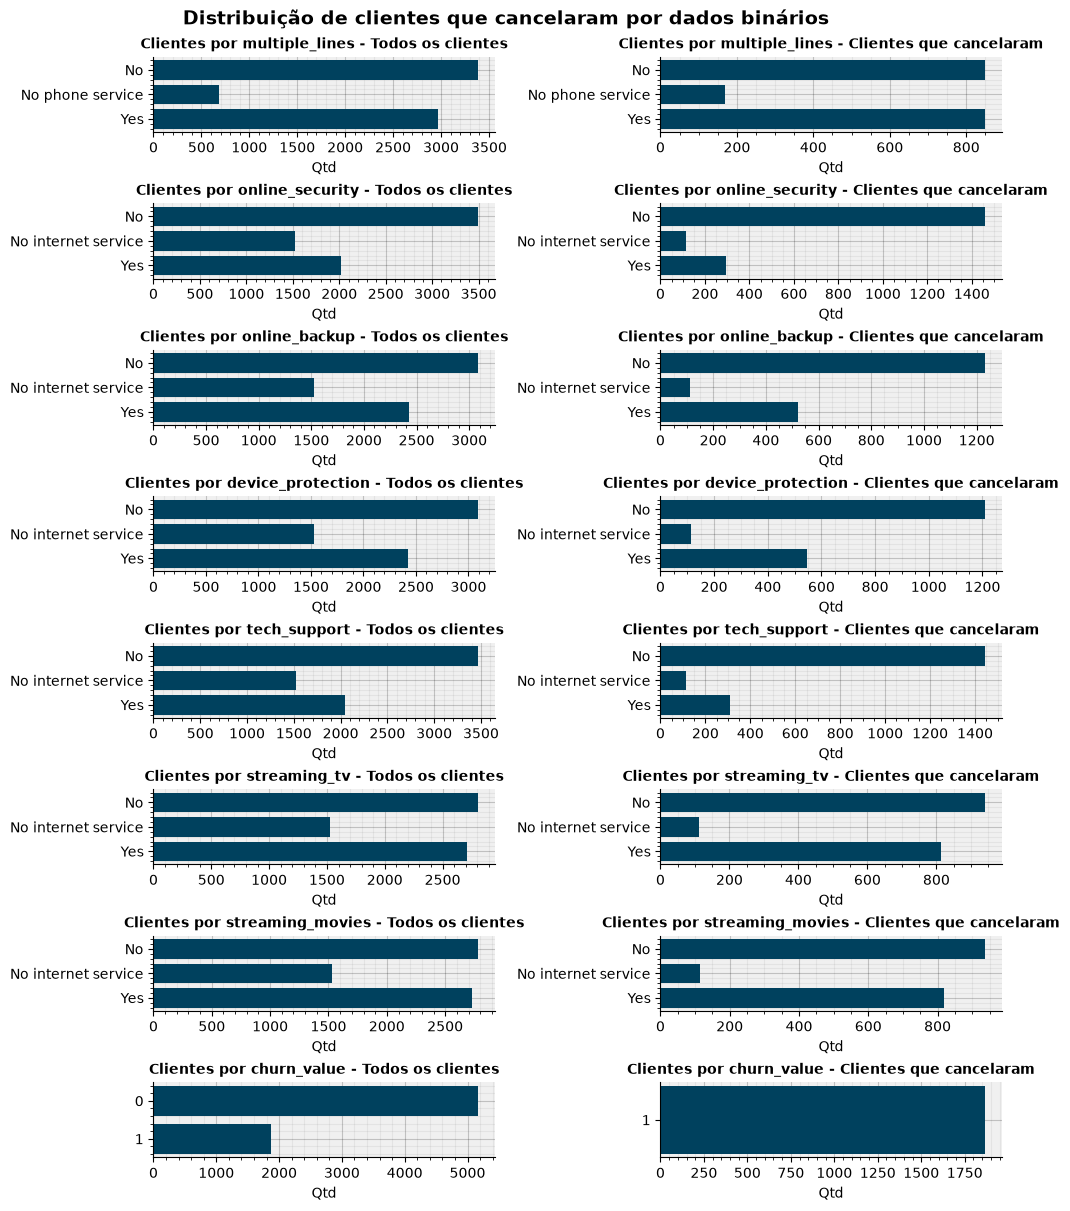

In [299]:
cols_analyzed = COLS_DEPENDANT_BINARIES + [COL_TARGET]

data_visualizer.plot_alternating_value_counts_barh(
    data1=df[cols_analyzed],
    data2=df_churn_only[cols_analyzed],
    data1_label='Todos os clientes',
    data2_label='Clientes que cancelaram',
    ncols = 2,
    figsize=(10, 12),
    fig_title='Distribuição de clientes que cancelaram por dados binários',
    # color_dict=label_color_dict,
    generic_color=generic_colors[0],
    title_args = title_ax_defaults,
    suptitle_args = title_fig_defaults,
    sort_alphabetically=True,
    max_categories=5
)
plt.show()

>- Não há relação definitiva entre o serviço de múltiplas linhas telefônicas e o cancelamento
>- Entre clientes que cancelaram, há uma proporção maior de clientes que não contratam o serviço de segurança digital
>- Entre clientes que cancelaram, há uma proporção maior de clientes que não contratam o serviço de backup
>- Entre clientes que cancelaram, há uma proporção maior de clientes que não contratam o serviço de proteção de dispositivo
>- Entre clientes que cancelaram, há uma proporção maior de clientes que não contratam o serviço de Tech Support
>- Não há relação definitiva entre os serviços de streaming e o cancelamento

>- 💡 **CONCLUSÃO**
>- ✅`online_security`, `online_backup`, `device_protection`, `tech_support` são variáveis de interesse
>- ❌`multiple_lines`, `streaming_tv` e `streaming_movies` devem ser descartadas.
>- ❓ Como temos poucos dados para clientes que não contratam internet e telefone, `No internet service` e `No phone service` devem ser descartados ou contabilizados na opção `No`
>- ❓ É possível que uma simples variável booleana que abrange se o cliente contrata qualquer serviço opcional ou não já seja o suficiente para o nosso modelo. 

In [300]:
df[COLS_NUMERICAL].dtypes

latitude           float64
longitude          float64
tenure_months        int64
total_charges       object
monthly_charges    float64
dtype: object

In [301]:
(df['total_charges'] == ' ').value_counts()

total_charges
False    7032
True       11
Name: count, dtype: int64

In [302]:
df[['monthly_charges', 'tenure_months', 'total_charges']].loc[df['total_charges'] == ' ']

,monthly_charges,tenure_months,total_charges
2234,52.55,0,
2438,20.25,0,
2568,80.85,0,
2667,25.75,0,
2856,56.05,0,
4331,19.85,0,
4687,25.35,0,
5104,20.00,0,
5719,19.70,0,
6772,73.35,0,


In [303]:
df[['monthly_charges', 'tenure_months', 'total_charges']].loc[df['tenure_months'] == 0]

,monthly_charges,tenure_months,total_charges
2234,52.55,0,
2438,20.25,0,
2568,80.85,0,
2667,25.75,0,
2856,56.05,0,
4331,19.85,0,
4687,25.35,0,
5104,20.00,0,
5719,19.70,0,
6772,73.35,0,


`total_charges` está nula onde `tenure_months` é 0. Podemos logicamente preencher esses valores faltantes com 0.

In [304]:
df['total_charges'] = df['total_charges'].replace(' ', 0).astype(float)

In [305]:
df[['monthly_charges', 'tenure_months', 'total_charges']].loc[df['tenure_months'] == 0]

,monthly_charges,tenure_months,total_charges
2234,52.55,0,0.0
2438,20.25,0,0.0
2568,80.85,0,0.0
2667,25.75,0,0.0
2856,56.05,0,0.0
4331,19.85,0,0.0
4687,25.35,0,0.0
5104,20.00,0,0.0
5719,19.70,0,0.0
6772,73.35,0,0.0


### 🔢 Variáveis numéricas

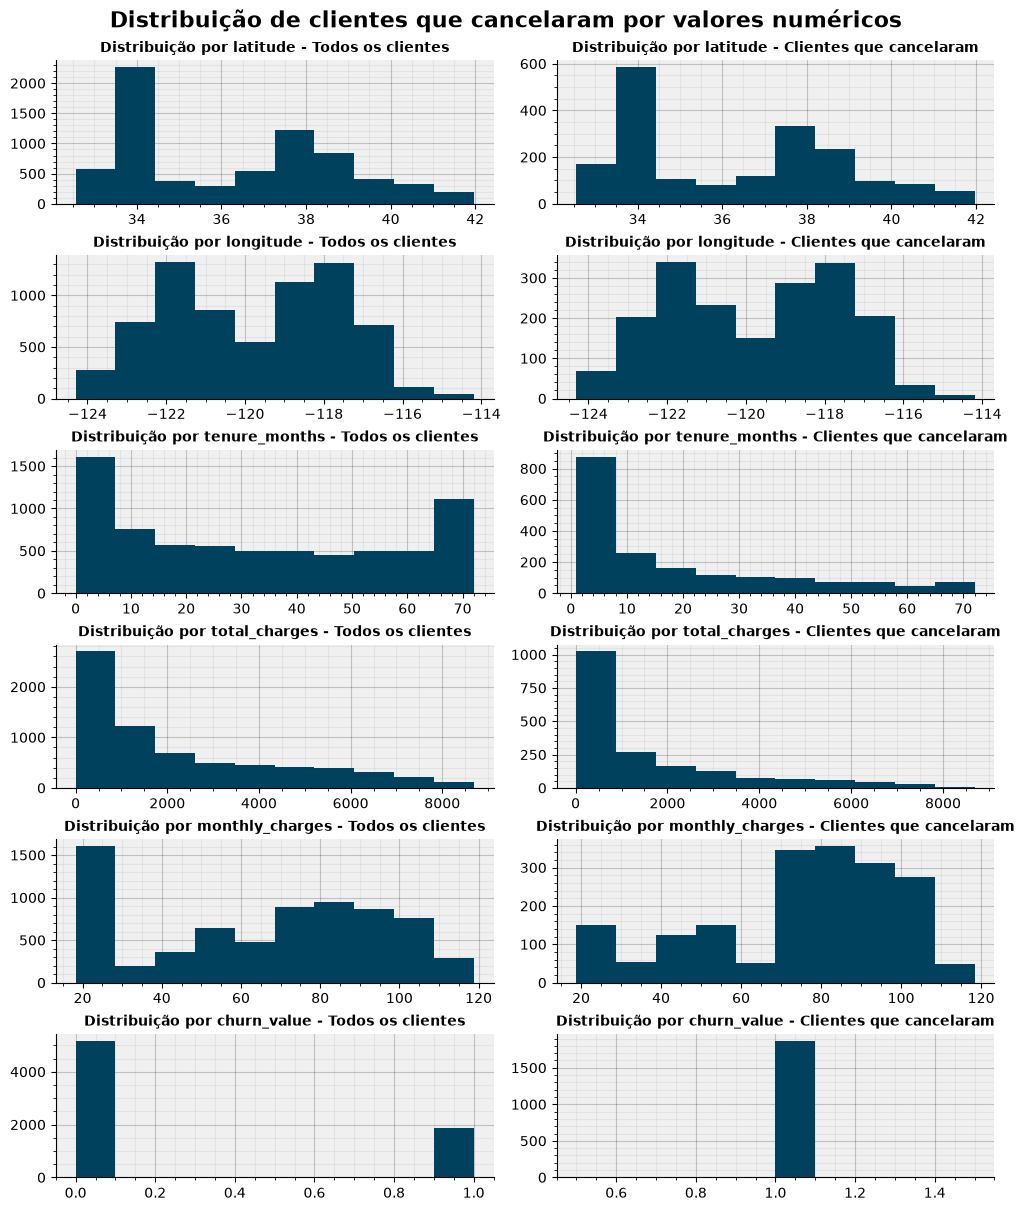

In [306]:
cols_analyzed = COLS_NUMERICAL + [COL_TARGET]

data_visualizer.plot_alternating_hist(
    data1=df[cols_analyzed],
    data2=df_churn_only[cols_analyzed],
    data1_label='Todos os clientes',
    data2_label='Clientes que cancelaram',
    ncols = 2,
    title_prefix='Distribuição por ',
    figsize=(10, 12),
    color=generic_colors[0],
    fig_title='Distribuição de clientes que cancelaram por valores numéricos',
    title_args = title_ax_defaults,
    )
plt.show()

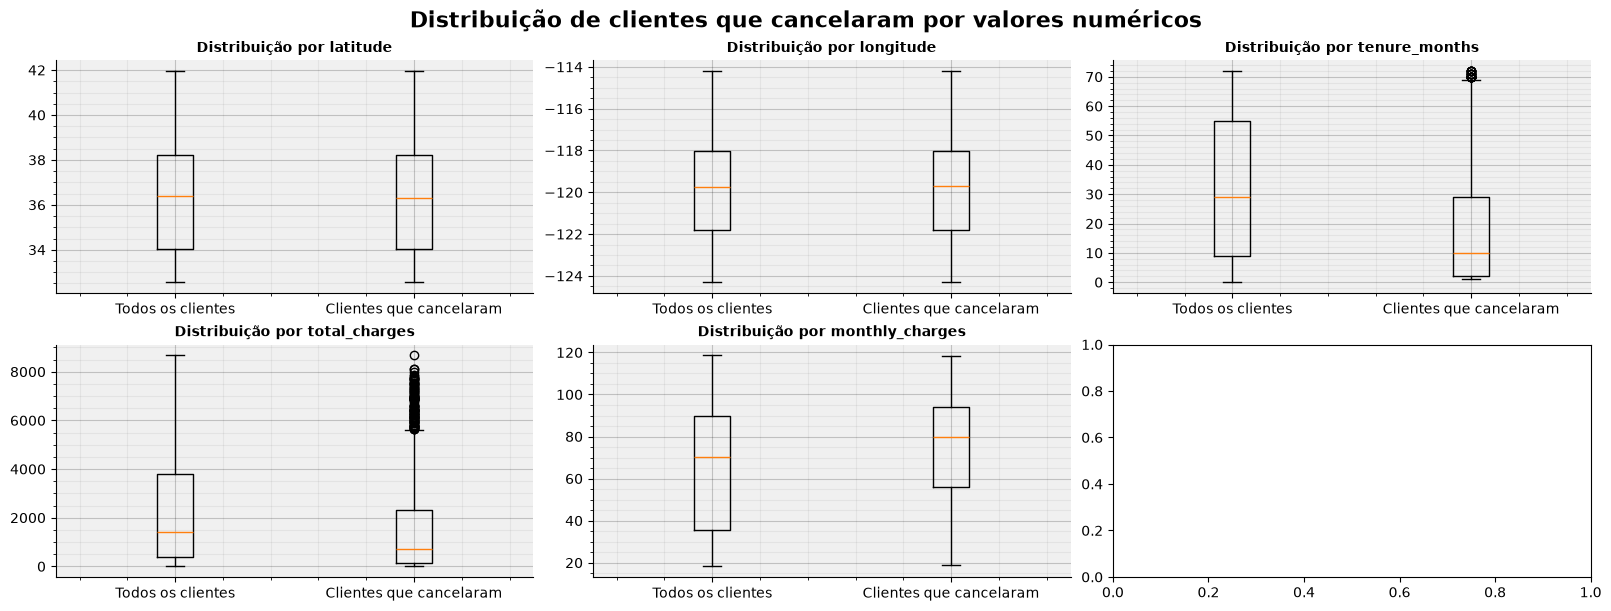

In [307]:
data_visualizer.plot_comparing_box(
    data1=df[COLS_NUMERICAL],
    data2=df_churn_only[COLS_NUMERICAL],
    data1_label='Todos os clientes',
    data2_label='Clientes que cancelaram',
    ncols = 3,
    title_prefix='Distribuição por ',
    figsize=(16, 6),
    fig_title='Distribuição de clientes que cancelaram por valores numéricos',
    title_args = title_ax_defaults,
)
plt.show()

>- Não há relação visível entre a posição geográfica e o cancelamento
>- Entre clientes que cancelaram, há uma proporção maior de clientes com menor tempo com a empresa
>- Não há relação definitiva entre a cobrança total e o cancelamento - A diferença em distribuição é melhor explicada por `tenure_months`
>- Entre clientes que cancelaram, há uma proporção maior de clientes com cobranças mensais maiores

>- 💡 **CONCLUSÃO**
>- ✅`tenure_months` e `monthly_charges` são variáveis de interesse
>- ❌`latitude`, `longitude` e `total_charges` devem ser descartadas.
>- ❓ Devemos checar a relação de `monthly_charges` com os serviços previamente examinados

## ❓ Pendências

### ❓ Como temos poucos dados para clientes que não contratam internet e telefone, `No internet service` e `No phone service` devem ser descartados ou contabilizados na opção `No`
Contabilizaremos como `No`.

In [308]:
COLS_DEPENDANT_BINARIES

['multiple_lines',
 'online_security',
 'online_backup',
 'device_protection',
 'tech_support',
 'streaming_tv',
 'streaming_movies']

In [309]:
col_dependencies

{'multiple_lines': 'phone_service',
 'online_security': 'internet_service',
 'online_backup': 'internet_service',
 'device_protection': 'internet_service',
 'tech_support': 'internet_service',
 'streaming_tv': 'internet_service',
 'streaming_movies': 'internet_service'}

In [310]:
dependencies_conversion : dict = {
    'No phone service': 'No',
    'No internet service': 'No'
}

In [311]:
temp = df[COLS_DEPENDANT_BINARIES + ['phone_service', 'internet_service']].replace(dependencies_conversion)

print(f'TODOS as contagens de valores')
print('='*10)
for col in col_dependencies.keys():
    display(temp[[col, col_dependencies.get(col)]].value_counts())

print(f'\nContagens de valores onde a dependência é NÃO')
print('='*10)
for col in col_dependencies.keys():
    display(temp[[col, col_dependencies.get(col)]].loc[df[col_dependencies.get(col)] == 'No'].value_counts())

TODOS as contagens de valores


multiple_lines  phone_service
No              Yes              3390
Yes             Yes              2971
No              No                682
Name: count, dtype: int64

online_security  internet_service
No               Fiber optic         2257
                 No                  1526
                 DSL                 1241
Yes              DSL                 1180
                 Fiber optic          839
Name: count, dtype: int64

online_backup  internet_service
No             Fiber optic         1753
               No                  1526
Yes            Fiber optic         1343
No             DSL                 1335
Yes            DSL                 1086
Name: count, dtype: int64

device_protection  internet_service
No                 Fiber optic         1739
                   No                  1526
Yes                Fiber optic         1357
No                 DSL                 1356
Yes                DSL                 1065
Name: count, dtype: int64

tech_support  internet_service
No            Fiber optic         2230
              No                  1526
              DSL                 1243
Yes           DSL                 1178
              Fiber optic          866
Name: count, dtype: int64

... (6 outputs left out)

device_protection  internet_service
No                 No                  1526
Name: count, dtype: int64

tech_support  internet_service
No            No                  1526
Name: count, dtype: int64

streaming_tv  internet_service
No            No                  1526
Name: count, dtype: int64

streaming_movies  internet_service
No                No                  1526
Name: count, dtype: int64

In [312]:
df[COLS_DEPENDANT_BINARIES + ['phone_service', 'internet_service']] = df[COLS_DEPENDANT_BINARIES + ['phone_service', 'internet_service']].replace(dependencies_conversion)

In [313]:
df.shape

(7043, 23)

### ❓ É possível que uma simples variável booleana que abrange se o cliente contrata qualquer serviço opcional ou não já seja o suficiente para o nosso modelo.

In [314]:
col_dependencies

{'multiple_lines': 'phone_service',
 'online_security': 'internet_service',
 'online_backup': 'internet_service',
 'device_protection': 'internet_service',
 'tech_support': 'internet_service',
 'streaming_tv': 'internet_service',
 'streaming_movies': 'internet_service'}

In [315]:
internet_services = [
    'online_security',
    'online_backup',
    'device_protection',
    'tech_support'
    ]
phone_services = [
    'multiple_lines'
]

df_services = df.copy(deep=True)

df_services['internet_service_extras'] = (df_services[internet_services] == 'Yes').any(axis=1)
df_services['phone_services_extras'] = (df_services[phone_services] == 'Yes').any(axis=1)
df_services['any_extra_service'] = (df_services[['internet_service_extras', 'phone_services_extras']] == True).any(axis=1)

df_services[internet_services + ['internet_service_extras'] + phone_services + ['phone_services_extras'] + ['any_extra_service']].head()

,online_security,online_backup,device_protection,tech_support,internet_service_extras,multiple_lines,phone_services_extras,any_extra_service
0,Yes,Yes,No,No,True,No,False,True
1,No,No,No,No,False,No,False,False
2,No,No,Yes,No,True,Yes,True,True
3,No,No,Yes,Yes,True,Yes,True,True
4,No,Yes,Yes,No,True,Yes,True,True


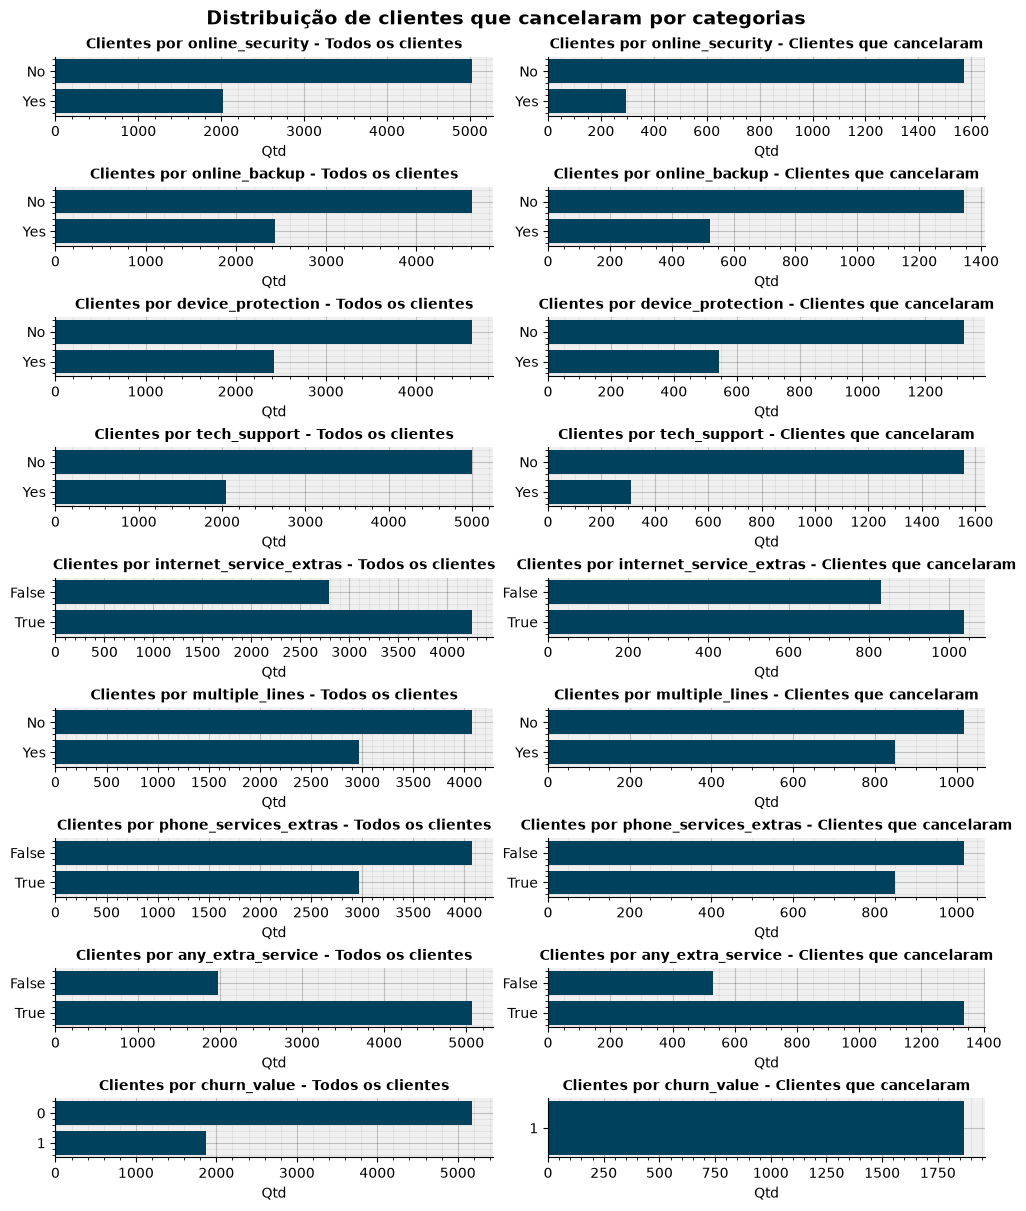

In [316]:
cols_to_analyze = internet_services + ['internet_service_extras'] + phone_services + ['phone_services_extras'] + ['any_extra_service'] + [COL_TARGET]
data_visualizer.plot_alternating_value_counts_barh(
    data1=df_services[cols_to_analyze],
    data2=df_services[cols_to_analyze].loc[df_services[COL_TARGET] == True],
    data1_label='Todos os clientes',
    data2_label='Clientes que cancelaram',
    ncols = 2,
    figsize=(10, 12),
    fig_title='Distribuição de clientes que cancelaram por categorias',
    # color_dict=label_color_dict,
    generic_color=generic_colors[0],
    title_args = title_ax_defaults,
    suptitle_args = title_fig_defaults,
    sort_alphabetically=True,
    max_categories=5
)
plt.show()

>- 💡**CONCLUSÕES**
>- ❌ `phone_services_extra` é redundante e será descartada com `phone_service` e `multiple_lines`.
>- ❌ `any_extra_service` não oferece sinal significante, será descartada
>- ❌ `internet_services_extra` não oferece um sinal melhor que seus compnentes, será descartada

Certificando que as colunas não entraram na DataFrame original:

In [317]:
[new_col in df.columns for new_col in ['phone_services_extra', 'internet_services_extra', 'any_extra_service']]

[False, False, False]

### ❓ Devemos checar a relação de `monthly_charges` com os serviços previamente examinados

In [318]:
df_monthly_charges = df.copy(deep=True)

In [319]:
dummies = pd.get_dummies(df_monthly_charges['internet_service'])
dummies.columns = data_loader.format_column_names(dummies.columns)
dummy_cols = ['dsl', 'fiber_optic', 'no']

dummies.head(3)

,dsl,fiber_optic,no
0,True,False,False
1,False,True,False
2,False,True,False


In [320]:
df_monthly_charges = pd.concat(
    [df_monthly_charges, dummies],
    axis=1
)

In [321]:
df_monthly_charges = df_monthly_charges.replace(
    {
        'No':0.0,
        False:0.0,
        'Yes':1.0,
        True:1.0
    }
)

In [322]:
df_monthly_charges[COLS_BINARY + COLS_DEPENDANT_BINARIES + dummy_cols] = df_monthly_charges[COLS_BINARY + COLS_DEPENDANT_BINARIES + dummy_cols].astype(float)

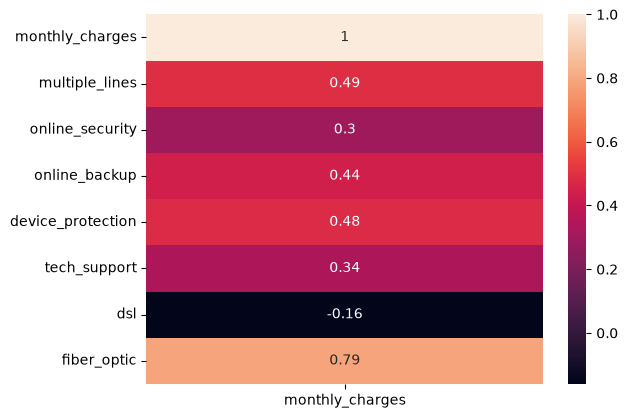

In [323]:
corr = df_monthly_charges[['monthly_charges'] + phone_services + internet_services + ['dsl', 'fiber_optic']].corr()
sns.heatmap(
    data=corr[['monthly_charges']],
    annot=True
)
plt.show()

>- 💡 **CONCLUSÕES**
>- 🔍 `monthly_charges` tem correlação moderada (>=0.3) com diversas variáveis, e uma correlação alta com `fiber_optic`. Ela pode ser mantida, mas é possível que certos modelos performem melhor sem ela. Deve ser investigado.

### ❓ Mapa de correlações

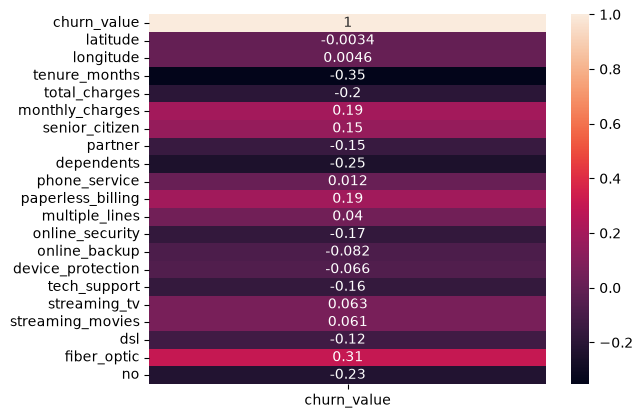

In [324]:
corr = df_monthly_charges.corr(numeric_only=True)
sns.heatmap(
    data=corr[[COL_TARGET]],
    annot=True
)
plt.show()

# 🧹 Tratamento de dados
Trataremos agora os dados, em uma DataFrame nova, para demonstrar o processo inteiro aqui nesse notebook e facilitar a construção da pipeline.

Nota-se que quando a Piperline final for construída em `src/pipeline.py`, seu `.fit` deve ser feito **apenas nos dados de treino**.

In [335]:
df.columns

Index(['churn_value', 'latitude', 'longitude', 'tenure_months',
       'total_charges', 'monthly_charges', 'gender', 'internet_service',
       'contract', 'payment_method', 'city', 'senior_citizen', 'partner',
       'dependents', 'phone_service', 'paperless_billing', 'multiple_lines',
       'online_security', 'online_backup', 'device_protection', 'tech_support',
       'streaming_tv', 'streaming_movies'],
      dtype='str')

In [336]:
df_final = data_loader.load_churn_data(PATH_DATA)

>- `internet_service`, `contract` e `payment_method` passarão por um processo de one-hot encoding
>- `Não` e `False` serão convertidos para `0.0`
>- `Yes` e `True` serão convertidos para `1.0`
>- Todas as colunas serão convertidas para `float64`

In [ ]:
class ColumnNameFormatter(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        self.feature_names_in_ = np.asarray(data_loader.format_column_names(X.columns), dtype=object)
        return self
    
    def transform(self, X):
        X = X.set_axis(data_loader.format_column_names(X.columns), axis=1)
        missing = set(self.feature_names_in_) - set(X.columns)
        if missing:
            raise ValueError(f'Missing columns present at fit: {sorted(missing)}')
        return X[list(self.feature_names_in_)]

    def get_feature_names_out(self, input_features=None):
        return self.feature_names_in_

class ToFloat(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
            self.feature_names_in_ = np.asarray(data_loader.format_column_names(X.columns), dtype=object)
            return self
    
    def transform(self, X):
        X_copy = X.copy()
        for col, series in X.items():
            if pd.api.types.is_string_dtype(series) or pd.api.types.is_object_dtype(series):
                X_copy[col] = series.str.lower()
                X_copy[col] = X_copy[col].replace({'yes':1, 'no':0}).astype(float)
            elif pd.api.types.is_bool_dtype(series) or pd.api.types.is_integer_dtype(series):
                X[col] = series.astype(float)
        return X_copy
        
    def get_feature_names_out(self, input_features=None):
        return self.feature_names_in_

In [371]:
# drop_cols = [
#     'customerid',
#     'count',
#     'country',
#     'state',
#     'city',
#     'zip_code',
#     'lat_long',
#     'churn_label',
#     'churn_score',
#     'cltv',
#     'churn_reason',
#     'gender',
#     'city',
#     'senior_citizen',
#     'phone_service',
#     'multiple_lines',
#     'streaming_tv',
#     'streaming_movies',
#     'latitude',
#     'longitude',
#     'total_charges'
# ]

demonstration_final_cols : list[str] = [
    'churn_value', # FOR THIS DEMONSTRATION ONLY
    'tenure_months',
    'monthly_charges',
    'internet_service',
    'contract',
    'payment_method',
    'partner',
    'dependents',
    'paperless_billing',
    'online_security',
    'online_backup',
    'device_protection',
    'tech_support'
    ]

keeper = ColumnTransformer(
    transformers=[('keep', 'passthrough', demonstration_final_cols)],
    remainder='drop',
    verbose_feature_names_out=False
)

column_transformer_initial = ColumnTransformer(
    transformers=[
        ('onehotencoder', OneHotEncoder(
                sparse_output=False,
                handle_unknown='ignore',
            ), onehot_cols),
        ('no collapse', CollapseIntoNo(), yesno_cols)
    ],
    remainder='passthrough',
    verbose_feature_names_out=False
)


In [ ]:
pipeline = Pipeline(steps=[
    ('format columns names', ColumnNameFormatter()),
    ('filter columns', keeper),
    ('encode and collapse no', column_transformer_initial),
    ('all to float', ToFloat())
]).set_output(transform='pandas')

_ = pipeline.fit_transform(df_final)
_

,internet_service_dsl,internet_service_fiber_optic,internet_service_no,contract_monthtomonth,contract_one_year,contract_two_year,payment_method_bank_transfer_automatic,payment_method_credit_card_automatic,payment_method_electronic_check,payment_method_mailed_check,online_security,online_backup,device_protection,tech_support,churn_value,tenure_months,monthly_charges,partner,dependents,paperless_billing
0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,1,2,53.85,0.0,0.0,1.0
1,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1,2,70.70,0.0,1.0,1.0
2,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1,8,99.65,0.0,1.0,1.0
3,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,1,28,104.80,1.0,1.0,1.0
4,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1,49,103.70,0.0,1.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,72,21.15,0.0,0.0,1.0
7039,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,1.0,0,24,84.80,1.0,1.0,1.0
7040,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0,72,103.20,1.0,1.0,1.0
7041,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0,11,29.60,1.0,1.0,1.0
